## **Graphics & Illustrations**

A chart is an argument: it answers **one question** about the data. Choose the chart by the question, not by the library.

| Question | Chart | Examples |
|---|---|---|
| How is **one** numerical attribute distributed? | Histogram, KDE, boxplot, ECDF, Q-Q plot | 03, 05, 08 - 11, 14, 16, Extra 10 |
| How do **two** numerical attributes relate? | Scatter, hexbin, joint plot, regression plot | 06, 07, 17, Extra 07 |
| What happens with **many** attributes at once? | Scatter matrix, pair plot, heatmap, parallel coordinates | 12, 13, 18, 24, Extra 05, Extra 06 |
| How does an attribute change **between classes**? | Boxplot, violin, KDE by hue, FacetGrid | 15, 20 - 23, Extra 01, Extra 02 |
| How **balanced** are the classes? | Count plot, donut | 04, 26 |
| Categories and part-to-whole? | Bar, mosaic | 01, 02, 27, Extra 03, Extra 04 |
| **Three or four** variables in one chart? | Bubble, 3D scatter | 19, 25 |

**Notebooks of this series:** 1. Manual Data Profiling · 2. Automatic Data Profiling · 3. Checking Issues in Dataframes · 4. Graphics & Illustrations · 5. EDA for Time Series

### **00. Import Libs and the DataSet**

In [3]:
#Import Specific Libs
from scipy import stats
from google.colab import files;
from collections import Counter;
from IPython.display import IFrame, display, HTML;

In [4]:
#Import the Others Libs
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import plotly.express as px
import seaborn as sns
import pandas as pd
import numpy as np
import re

In [5]:
#Import Statistical and Time Series Libs
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.graphics.mosaicplot import mosaic
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [6]:
#Ignore Error Message
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [7]:
#Import Dataframe from Github
df = pd.read_csv('https://raw.githubusercontent.com/jrafa1607/DataScience-ML-AI/main/-%20Datasets/credit_data.csv')

**Attention!** The attributes are renamed exactly as in the *Manual Data Profiling* notebook, so every notebook of the series uses the same names: `Index`, `income`, `age`, `loan` and `result`.

In [11]:
#Define New Attributes Names
df.columns = ['id', 'income', 'age', 'loan', 'result']
df.head(3)

,id,income,age,loan,result
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [12]:
#Change the Name of the Specific Attribute
df = df.rename(columns={df.columns[0]: "Index"})
df.head(3)

,Index,income,age,loan,result
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [20]:
#Define the Numerical Attributes and the Target
num_cols = ['income', 'age', 'loan']
target = 'result'

### **01. Graphics & Illustrations**

**Attention!** The examples use the dataframe exactly as it comes: `age` still has 3 missing values ( ignored by the plots ) and 3 negative values ( plotted as real values, so they appear as extreme points ).
Look for them in the charts: a graphic is also a data quality tool.

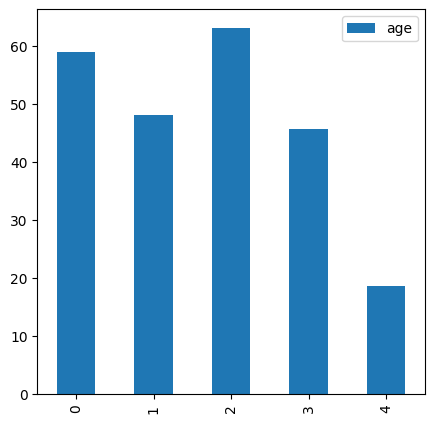

In [32]:
#Example 01
df[['age']].head(5).plot.bar(figsize=(5, 5));

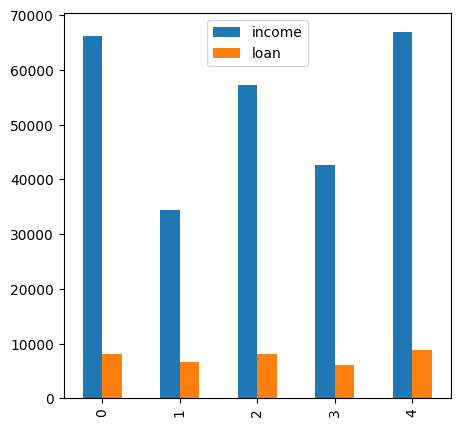

In [33]:
#Example 02
df[['income', 'loan']].head(5).plot.bar(figsize=(5, 5));

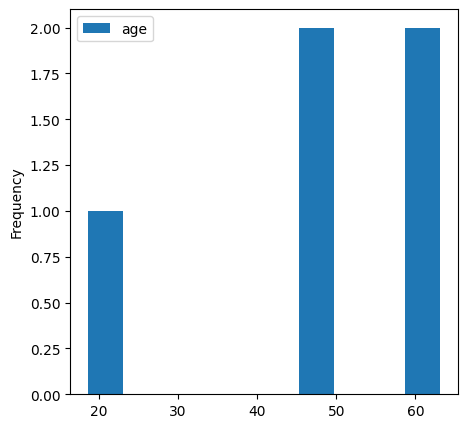

In [34]:
#Example 03
df[['age']].head(5).plot.hist(figsize=(5, 5));

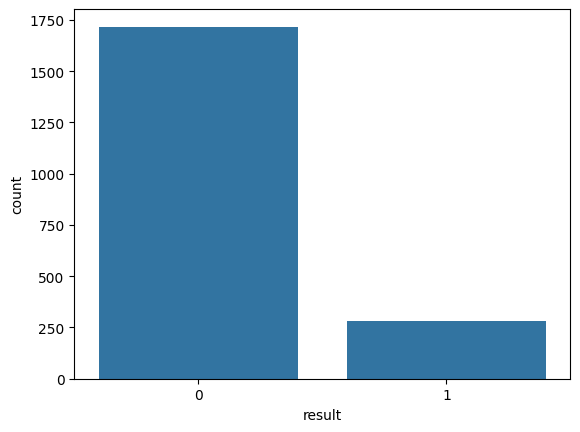

In [35]:
#Example 04
sns.countplot(x = df['result']);

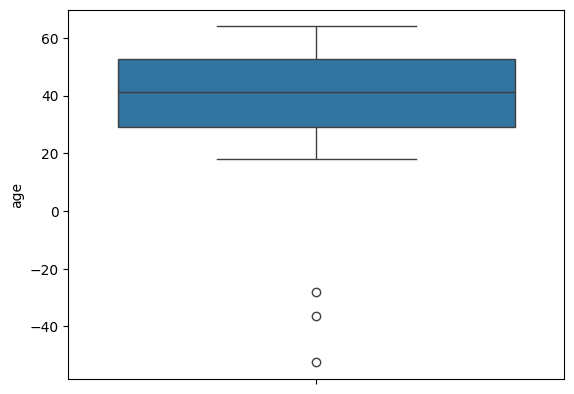

In [36]:
#Example 05 ( Attribute Distribution )
sns.boxplot(df.age);

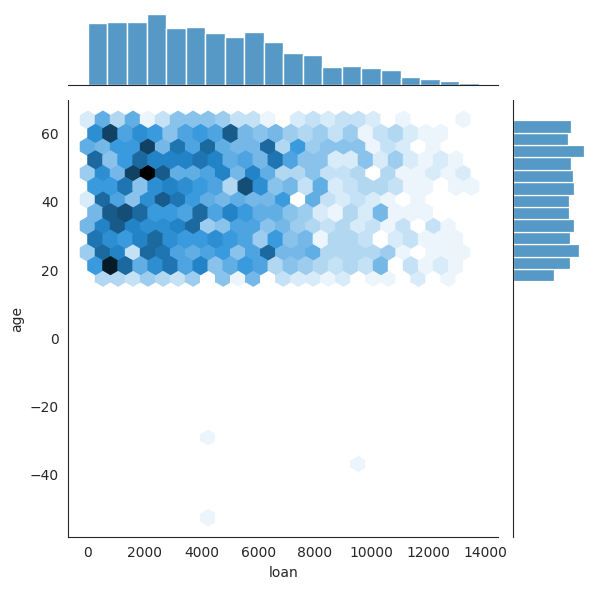

In [37]:
#Example 06 ( Another Attribute Distribution )
with sns.axes_style('white'):
    sns.jointplot(x = df['loan'], y = df['age'], kind='hex');

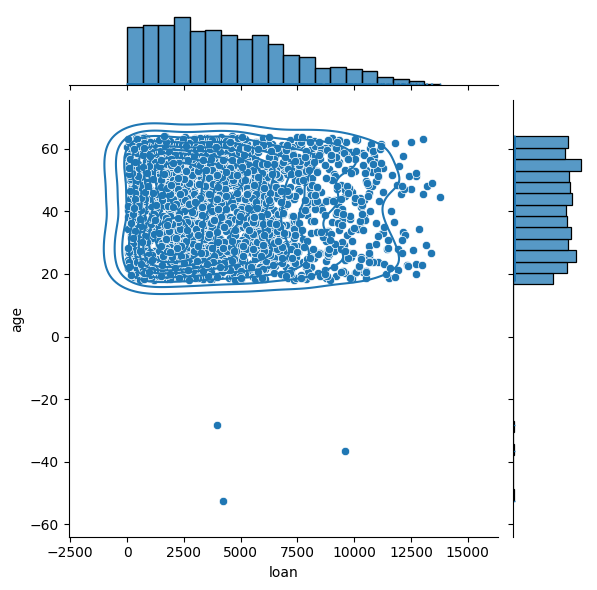

In [38]:
#Example 07 ( Another Attribute Distribution )
sns.jointplot(data=df, x='loan', y='age').plot_joint(sns.kdeplot).plot_marginals(sns.rugplot);

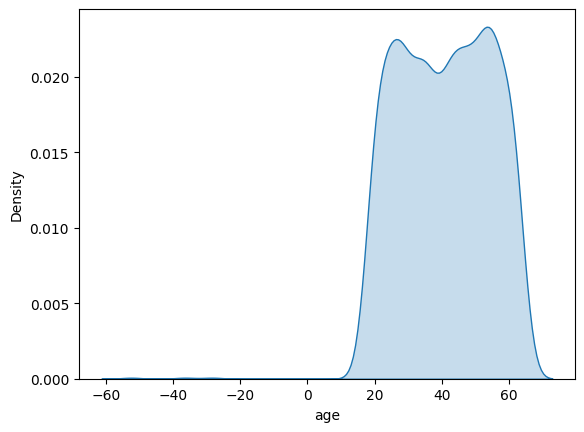

In [39]:
#Example 08 ( Histogram )
sns.kdeplot(x = df['age'], shade=True);

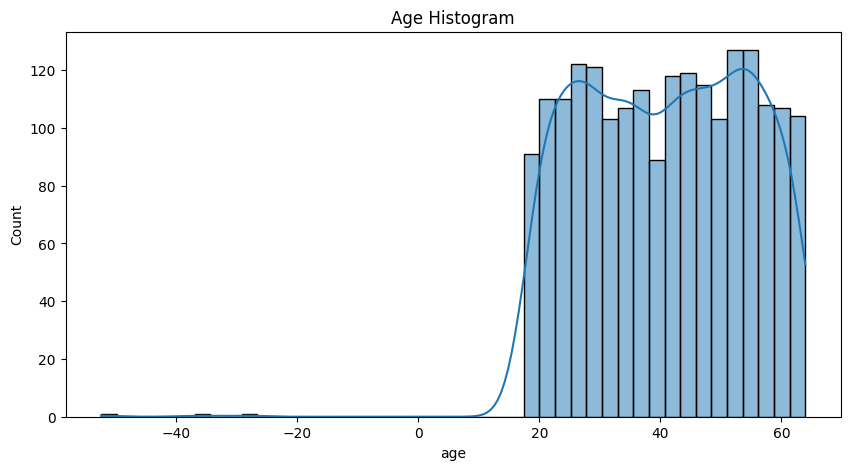

In [40]:
#Example 09 ( Another Example of Histogram )
plt.figure(figsize=(10,5));
sns.histplot(df["age"], kde=True, bins=45)
plt.title("Age Histogram");

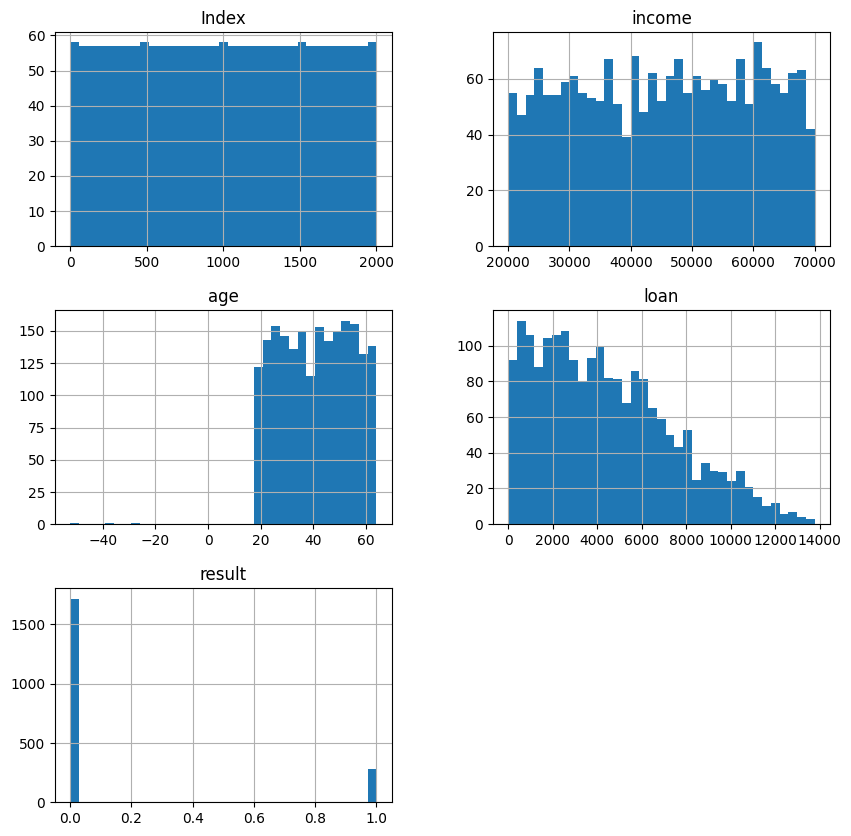

In [41]:
#Example 10 ( All Histograms )
df.hist(bins=35, figsize=(10, 10))
plt.show()

<Axes: xlabel='age', ylabel='Count'>

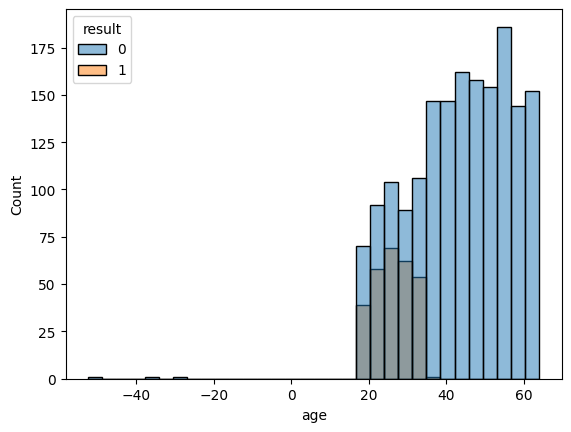

In [42]:
#Example 11 ( Combine Histograms )
sns.histplot(data=df, x="age", hue="result")

In [43]:
#Example 12 ( Scatter Matrix )
graph = px.scatter_matrix(df, dimensions=['age', 'income', 'loan'], color = 'result')
graph.show()

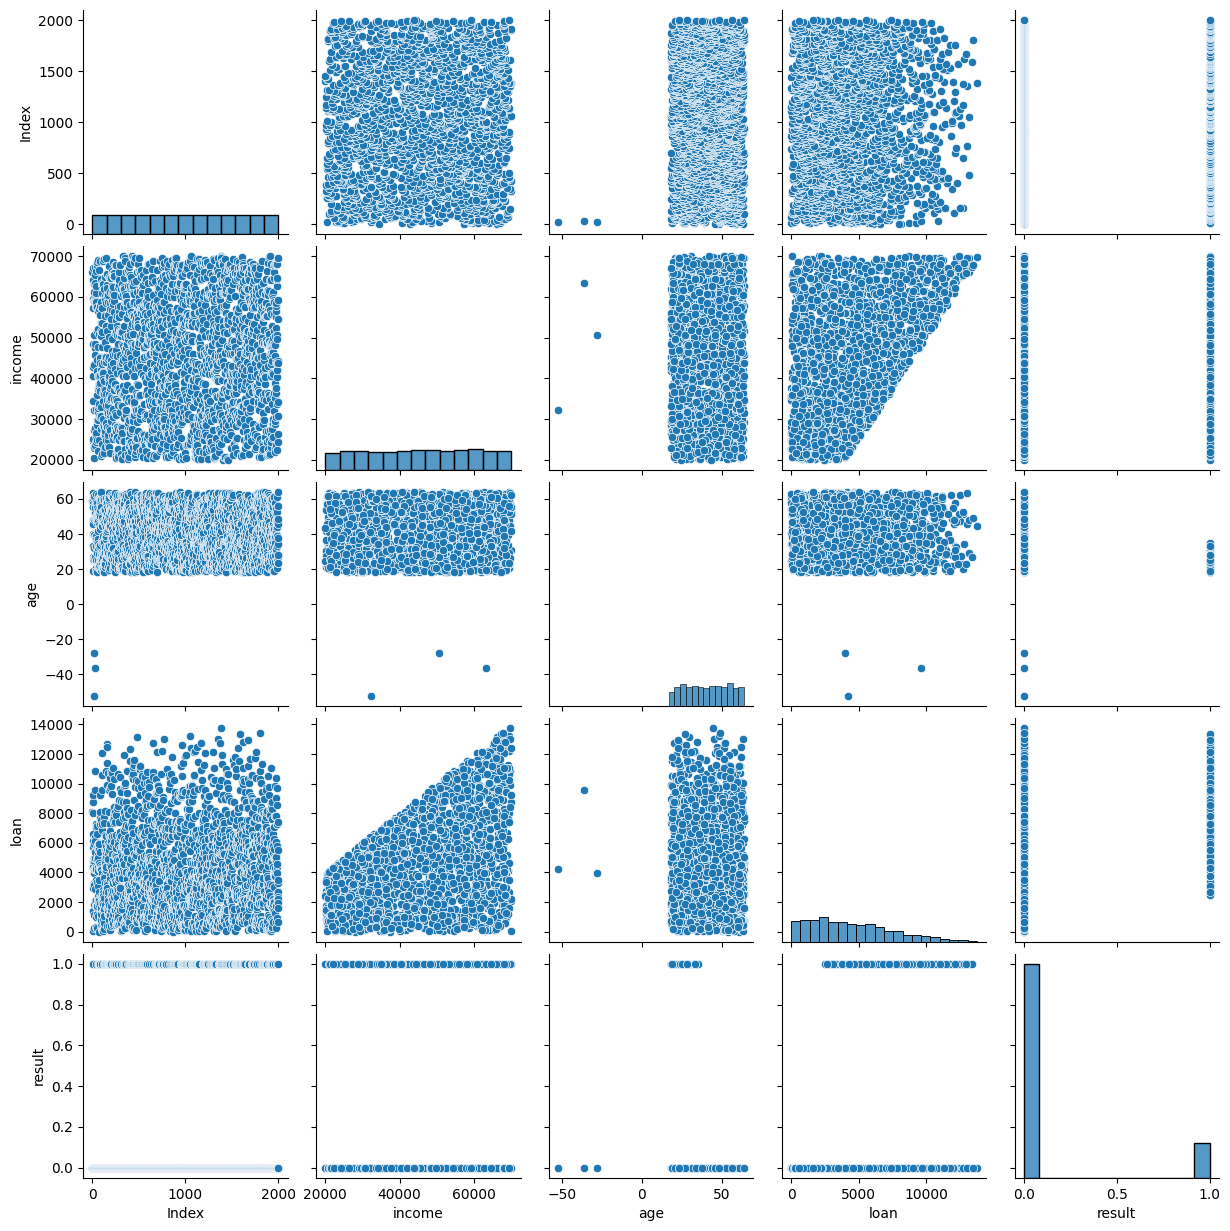

In [44]:
#Example 13 ( Full Fair Plot )
sns.pairplot(df);

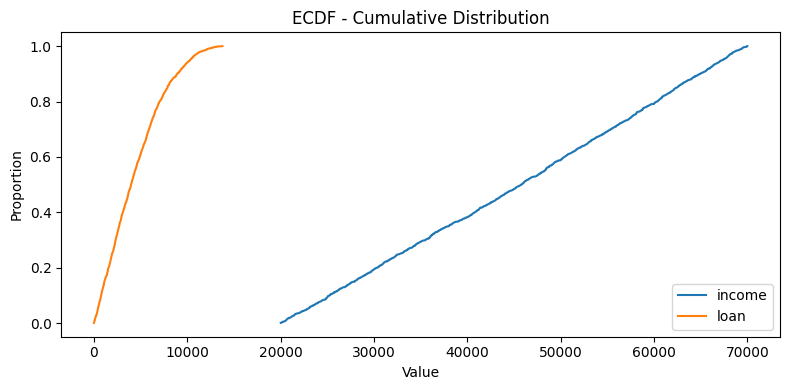

In [45]:
#Example 14 ECDF (Empirical Cumulative Distribution Function)
fig, ax = plt.subplots(figsize=(8, 4))

for col in ['income', 'loan']:
    # Remove Null Values // Sort Values for ECDF
    s = df[col].dropna().sort_values()
    ax.plot(s.values, np.arange(1, len(s) + 1) / len(s), label=col)

ax.set_title('ECDF - Cumulative Distribution')
ax.set_xlabel('Value')
ax.set_ylabel('Proportion')
ax.legend()
plt.tight_layout()
plt.show()

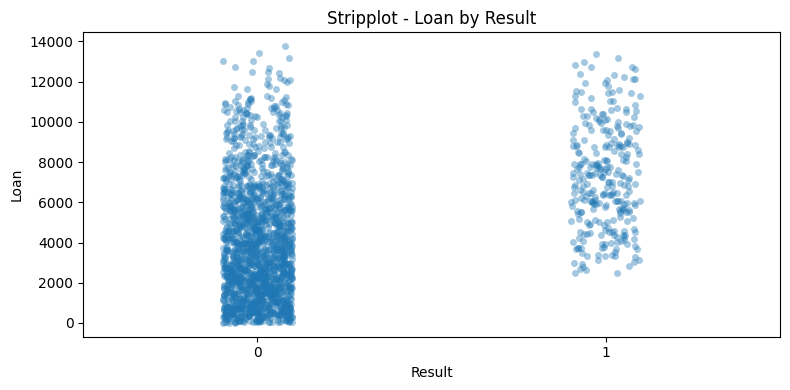

In [46]:
# Example 15 with Stripplot
plt.figure(figsize=(8, 4))
sns.stripplot(data=df.dropna(), x='result', y='loan', alpha=0.4)
plt.title('Stripplot - Loan by Result')
plt.xlabel('Result')
plt.ylabel('Loan')
plt.tight_layout()
plt.show()

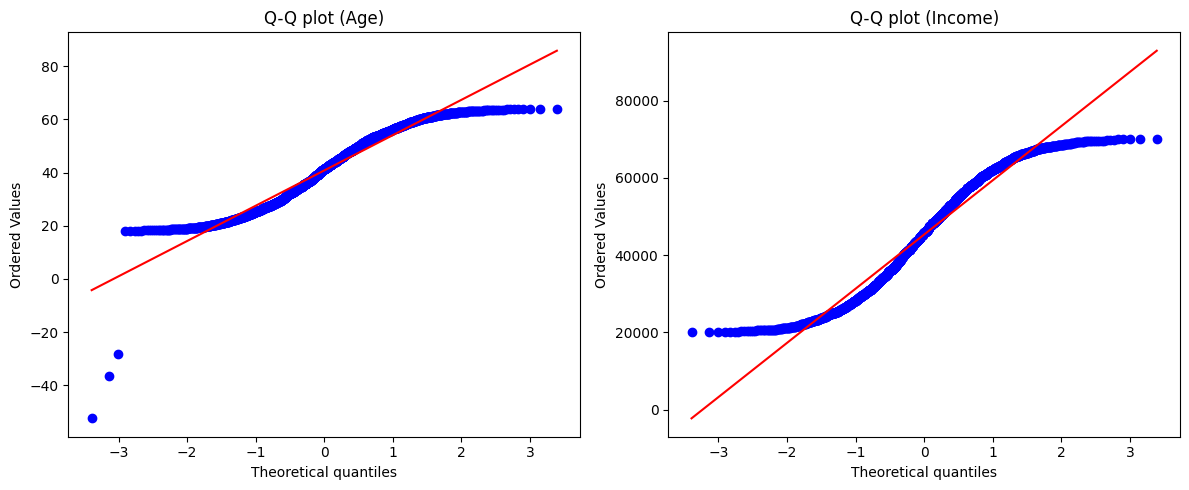

In [47]:
#Example 16 with Q-Q (Quantile-Quantile)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
stats.probplot(df['age'].dropna(), dist='norm', plot=axes[0])
axes[0].set_title('Q-Q plot (Age)')
stats.probplot(df['income'].dropna(), dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot (Income)')
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Regplot: Income vs Loan')

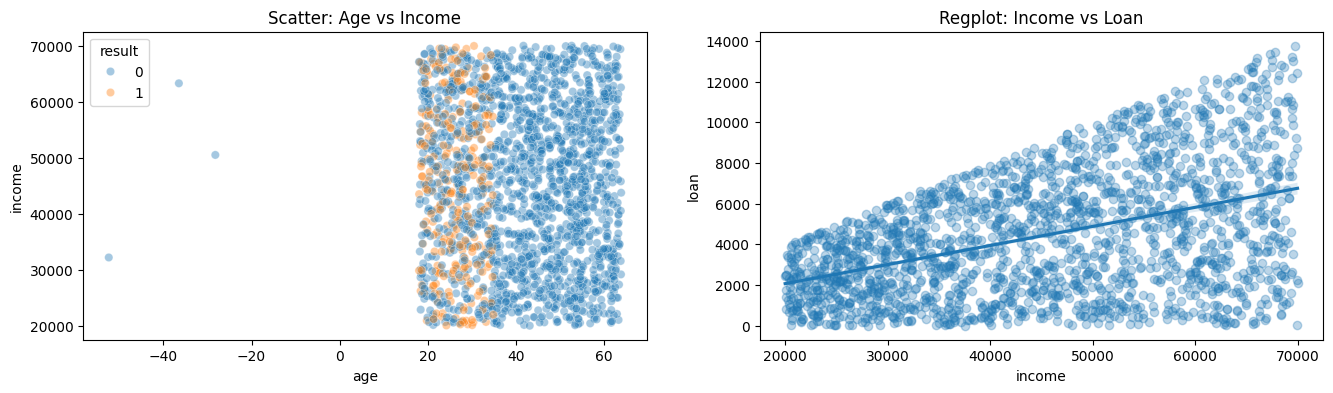

In [48]:
#Example 17 ( Multiple Scatter Plots )
fig, axes = plt.subplots(1, 2, figsize=(16,4))
sns.scatterplot(data=df, x='age', y='income', hue='result', alpha=0.4, ax=axes[0])
axes[0].set_title('Scatter: Age vs Income')
sns.regplot(data=df, x='income', y='loan', scatter_kws={'alpha':0.3}, ax=axes[1])
axes[1].set_title('Regplot: Income vs Loan')

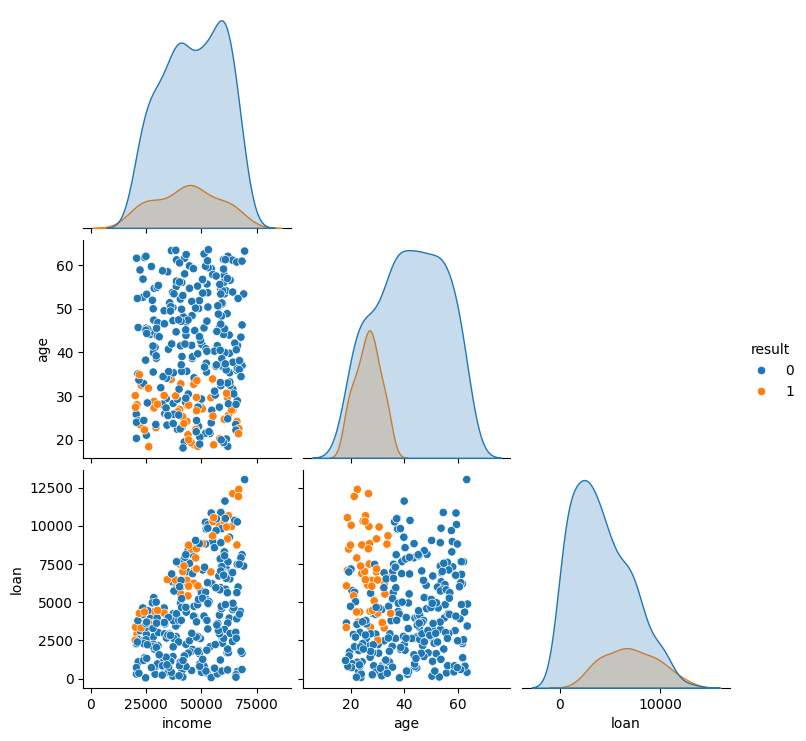

In [49]:
#Example 18 - Multivariate Analysis using Credit Dataset
sns.pairplot(df.sample(300, random_state=42)[['income', 'age', 'loan', 'result']], hue='result', diag_kind='kde', corner=True)
plt.show()

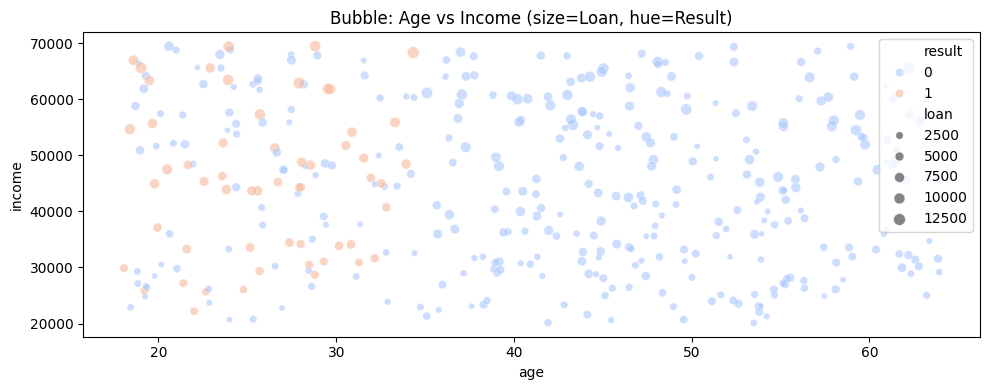

In [50]:
#Example 19 - Bubble
fig, ax = plt.subplots(figsize=(10,4))
sns.scatterplot(data=df.sample(400, random_state=3), x='age', y='income', size='loan', hue='result', palette='coolwarm', alpha=0.6, ax=ax)
ax.set_title('Bubble: Age vs Income (size=Loan, hue=Result)')
plt.tight_layout()
plt.show()

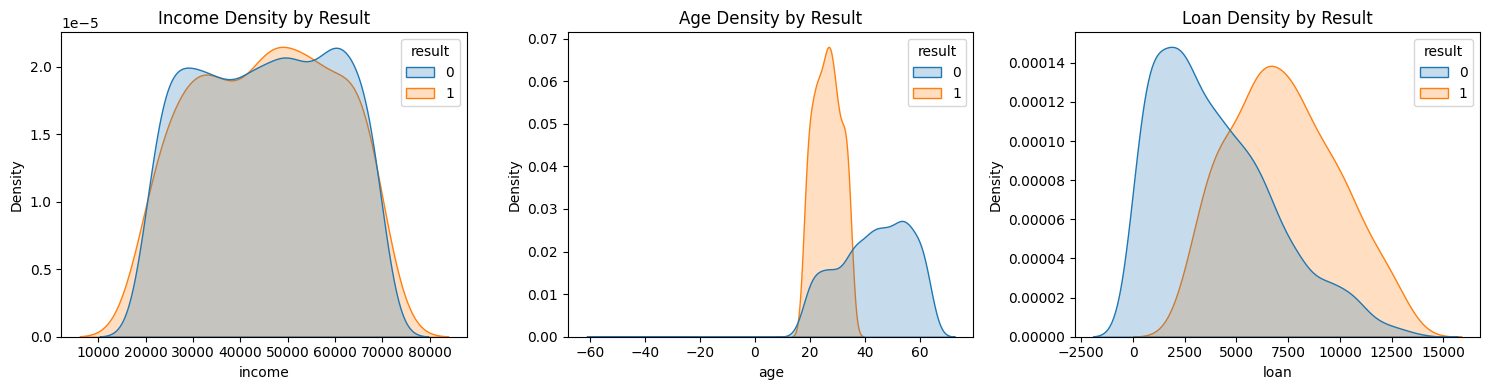

In [51]:
#Example 20 ( Density by Result )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.kdeplot(data=df, x='income', hue='result', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Income Density by Result')

sns.kdeplot(data=df, x='age', hue='result', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Age Density by Result')

sns.kdeplot(data=df, x='loan', hue='result', fill=True, common_norm=False, ax=axes[2])
axes[2].set_title('Loan Density by Result')

plt.tight_layout()
plt.show()

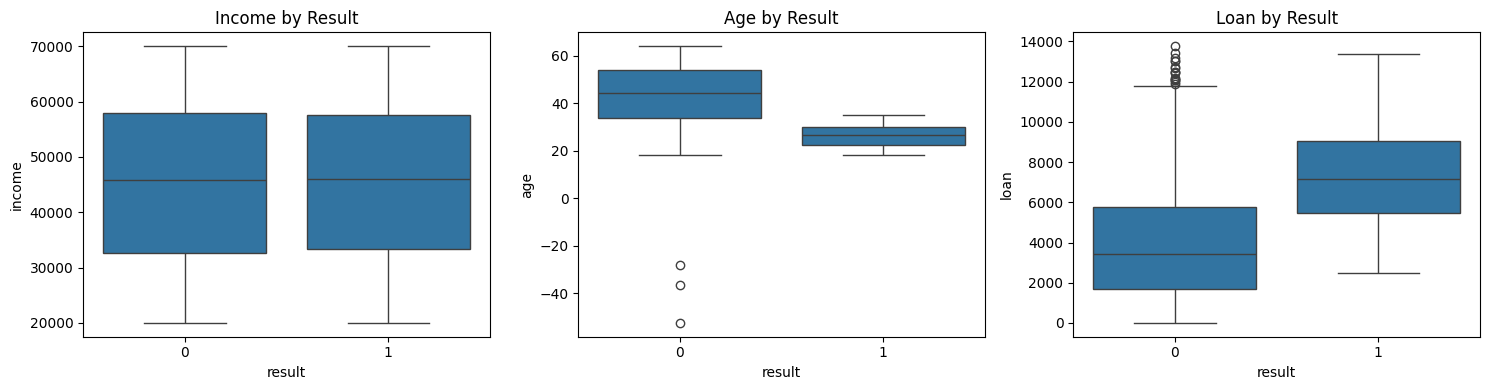

In [52]:
#Example 21 ( Boxplots by Result )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='result', y=col, ax=ax)
    ax.set_title(f'{col.capitalize()} by Result')
plt.tight_layout()
plt.show()

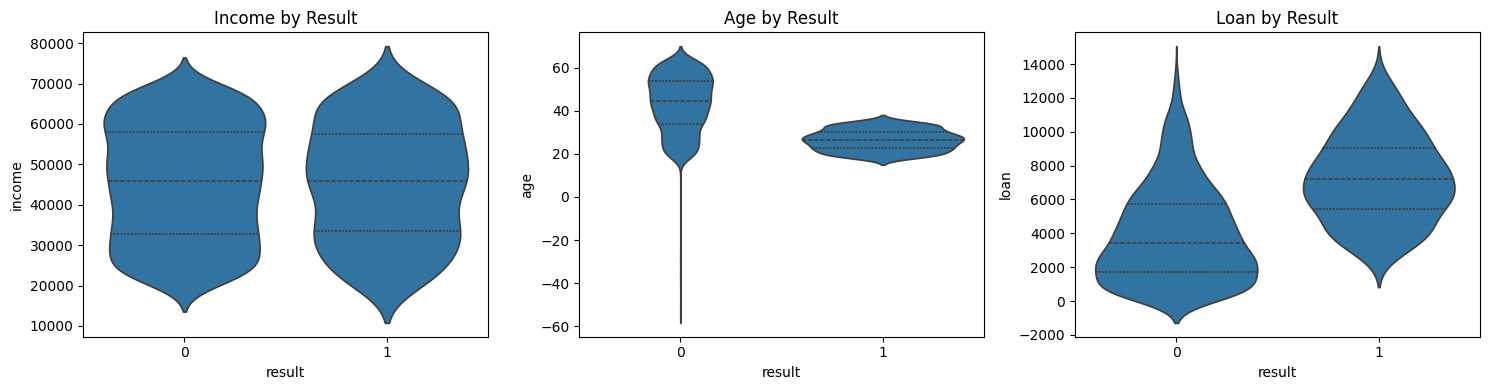

In [53]:
#Example 22 ( Violin Plots by Result )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.violinplot(data=df, x='result', y=col, inner='quartile', ax=ax)
    ax.set_title(f'{col.capitalize()} by Result')
plt.tight_layout()
plt.show()

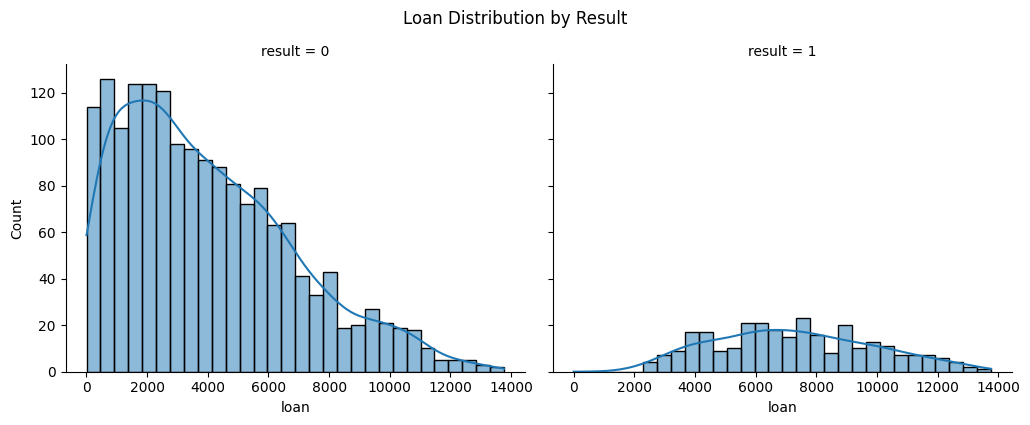

In [54]:
#Example 23 ( Histograms by Result with FacetGrid )
g = sns.displot(data=df, x='loan', col='result', kde=True, bins=30, height=4, aspect=1.3)
g.fig.suptitle('Loan Distribution by Result', y=1.05)
plt.show()

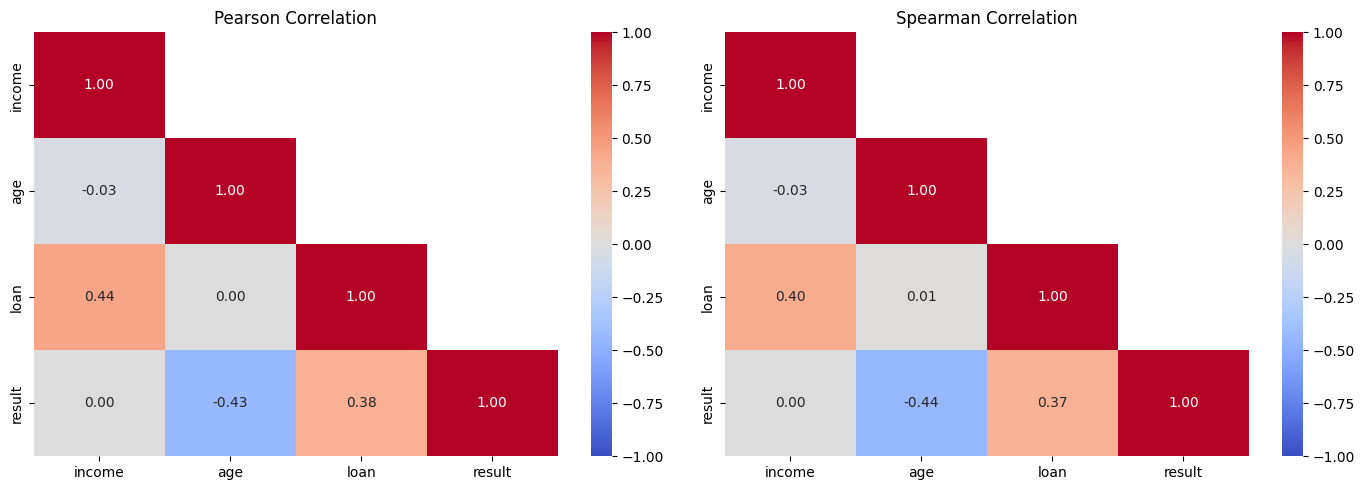

In [55]:
#Example 24 ( Correlation Heatmap: Pearson vs Spearman )
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ['pearson', 'spearman']):
    corr = df[num_cols + ['result']].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # Hide the Repeated Upper Triangle
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'{method.capitalize()} Correlation')
plt.tight_layout()
plt.show()

In [56]:
#Example 25 ( 3D Scatter Plot )
sample = df.dropna().sample(500, random_state=42).astype({'result': str})
fig = px.scatter_3d(sample, x='age', y='income', z='loan', color='result', opacity=0.7)
fig.show()

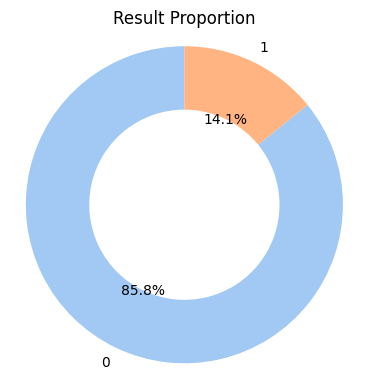

Imbalance ratio ( majority : minority ) = 6.1 : 1


In [57]:
#Example 26 ( Donut Chart and Class Imbalance Ratio )
counts = df['result'].value_counts()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'), wedgeprops={'width': 0.4})
ax.axis('equal')
ax.set_title('Result Proportion')
plt.show()
print(f'Imbalance ratio ( majority : minority ) = {counts.max() / counts.min():.1f} : 1')

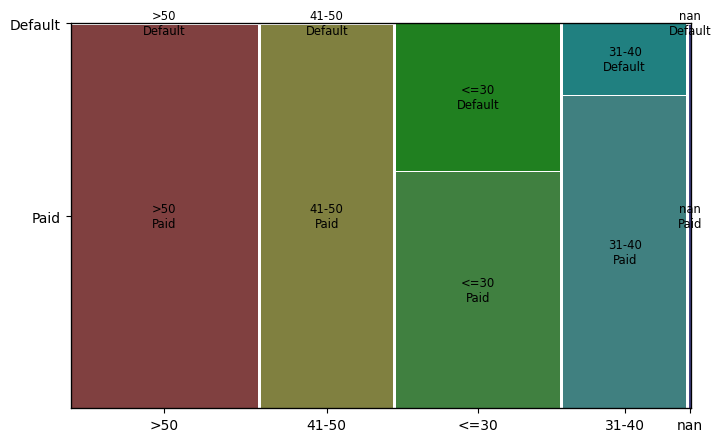

In [58]:
#Example 27 ( Mosaic Plot - Age Group vs Result )
temp_df = df.copy()
temp_df['age_group'] = pd.cut(
    temp_df['age'],
    bins=[0, 30, 40, 50, 120],
    labels=['<=30', '31-40', '41-50', '>50']
).astype(str)

temp_df['result_label'] = temp_df['result'].map({0: 'Paid', 1: 'Default'}).astype(str)
fig, ax = plt.subplots(figsize=(8, 5))
mosaic(temp_df, ['age_group', 'result_label'], ax=ax)
plt.show()

### **02. Extra Graphics & Illustrations**

In [ ]:
#Extra 01 ( ECDF by Result )
# If the curves of the two classes are far apart, the attribute separates them well ( the largest vertical gap is the KS statistic )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.ecdfplot(data=df, x=col, hue='result', ax=ax)
    ax.set_title(f'ECDF of {col.capitalize()} by Result')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 02 ( Boxen Plots by Result - More Detail than a Boxplot in Larger Samples )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxenplot(data=df, x='result', y=col, ax=ax)
    ax.set_title(f'{col.capitalize()} by Result')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 03 ( Default Rate by Age Group with 95% Confidence Interval )
# The error bars show how uncertain each rate is: small groups have wide intervals
def wilson_ci(successes, n, z=1.96):
    p = successes / n
    center = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    margin = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return center - margin, center + margin

age_group = pd.cut(df['age'], bins=[0, 30, 40, 50, 120], labels=['<=30', '31-40', '41-50', '>50'])
rate = df.groupby(age_group, observed=False)[target].agg(defaults='sum', total='count')
rate['default_rate'] = rate['defaults'] / rate['total']
rate['ci_low'], rate['ci_high'] = wilson_ci(rate['defaults'], rate['total'])

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rate.index.astype(str), rate['default_rate'] * 100, color=sns.color_palette('pastel')[0],
       yerr=[(rate['default_rate'] - rate['ci_low']) * 100, (rate['ci_high'] - rate['default_rate']) * 100], capsize=5)
ax.set_title('Default Rate by Age Group ( 95% Wilson Interval )')
ax.set_xlabel('Age group')
ax.set_ylabel('Default rate ( % )')
plt.tight_layout()
plt.show()
rate.round(3)

In [ ]:
#Extra 04 ( Default Rate Heatmap: Age Group x Income Quartile )
income_quartile = pd.qcut(df['income'], 4, labels=['Q1 ( low )', 'Q2', 'Q3', 'Q4 ( high )'])
heat = df.pivot_table(index=age_group, columns=income_quartile, values=target, aggfunc='mean', observed=False) * 100

plt.figure(figsize=(7, 4))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Default rate ( % )'})
plt.title('Default Rate ( % ): Age Group x Income Quartile')
plt.xlabel('Income quartile')
plt.ylabel('Age group')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 05 ( Clustermap - Correlated Attributes Grouped Together )
sns.clustermap(df[num_cols + [target]].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, figsize=(5, 5))
plt.show()

In [ ]:
#Extra 06 ( Parallel Coordinates - Each Line Is One Client )
# Min-max scaling puts all the attributes on the same axis | lines of the same class that stay together reveal a pattern
sample = df.dropna().sample(300, random_state=42)[num_cols + [target]]
scaled = sample.copy()
scaled[num_cols] = (sample[num_cols] - sample[num_cols].min()) / (sample[num_cols].max() - sample[num_cols].min())
scaled[target] = scaled[target].map({0: 'Paid', 1: 'Default'})
scaled = scaled.sort_values(target, ascending=False)     # Paid first, so the Default lines are drawn on top

plt.figure(figsize=(8, 4))
pd.plotting.parallel_coordinates(scaled, target, color=['#4C72B0', '#C44E52'], alpha=0.4)
plt.title('Parallel Coordinates ( Min-Max Scaled )')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 07 ( Hexbin - Density of Income vs Loan )
# Hexagons replace thousands of overlapping points: a darker hexagon means more clients
df.plot.hexbin(x='income', y='loan', gridsize=25, cmap='viridis', figsize=(7, 5))
plt.title('Hexbin: Income vs Loan')
plt.show()

In [ ]:
#Extra 08 ( Interactive Histogram with Marginal Boxplot - Plotly )
fig = px.histogram(df.astype({'result': str}), x='income', color='result', marginal='box', barmode='overlay', nbins=40, opacity=0.6)
fig.show()

In [ ]:
#Extra 09 ( Mini Dashboard - Four Views in One Figure )
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.countplot(x=df['result'], ax=axes[0, 0])
axes[0, 0].set_title('Class Balance')
sns.histplot(df['age'].dropna(), kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Age Distribution')
sns.boxplot(data=df, x='result', y='loan', ax=axes[1, 0])
axes[1, 0].set_title('Loan by Result')
sns.scatterplot(data=df.sample(500, random_state=1), x='income', y='loan', hue='result', alpha=0.5, ax=axes[1, 1])
axes[1, 1].set_title('Income vs Loan')
plt.suptitle('Credit Data - Overview', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
#Extra 10 ( Annotated Chart - Mean, Median and Outlier Fences )
age_values = df['age'].dropna()
q1, q3 = age_values.quantile([0.25, 0.75])

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(age_values, bins=40, ax=ax, color='lightsteelblue')
ax.axvline(age_values.mean(), color='red', linestyle='--', label=f'Mean = {age_values.mean():.1f}')
ax.axvline(age_values.median(), color='green', linestyle='-', label=f'Median = {age_values.median():.1f}')
ax.axvline(q1 - 1.5 * (q3 - q1), color='gray', linestyle=':', label='IQR lower fence')
ax.axvline(q3 + 1.5 * (q3 - q1), color='gray', linestyle=':', label='IQR upper fence')
ax.set_title('Age Distribution with Reference Lines')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
#Extra 11 ( Making a Data Issue Visible - Negative Ages in Red )
invalid = df['age'] < 0

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(df.index[~invalid], df.loc[~invalid, 'age'], s=8, alpha=0.5, label='Valid or missing')
ax.scatter(df.index[invalid], df.loc[invalid, 'age'], s=60, color='red', label=f'Negative age ( {invalid.sum()} )')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Age by Row Position')
ax.set_xlabel('Row')
ax.set_ylabel('Age')
ax.legend()
plt.tight_layout()
plt.show()

### **03. Style, Color and Saving Figures**

In [ ]:
#Extra 12 ( Color Palettes - Qualitative, Sequential and Diverging )
# Qualitative: categories without order | Sequential: low to high | Diverging: negative to positive around a center ( e.g. correlations )
palettes = {'Qualitative ( categories )': 'colorblind', 'Sequential ( low to high )': 'viridis', 'Diverging ( negative to positive )': 'coolwarm'}

fig, axes = plt.subplots(3, 1, figsize=(7, 2.6))
for ax, (title, name) in zip(axes, palettes.items()):
    ax.bar(range(7), [1] * 7, color=sns.color_palette(name, 7), width=1)
    ax.set_title(title, fontsize=10, loc='left')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 13 ( Customizing the Style and Saving the Figure )
# The context managers change the style only inside the block: the other charts of the notebook are not affected
with sns.axes_style('whitegrid'), sns.plotting_context('talk'):
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.kdeplot(data=df, x='age', hue='result', fill=True, common_norm=False, ax=ax)
    ax.set_title('Age Density by Result')
    fig.savefig('age_density_by_result.png', dpi=150, bbox_inches='tight')
plt.show()

### **Good Practices for Graphics**

- **One chart, one question.** Write the question in the title or in the cell comment.
- **Label everything:** title, axes, units and legend; a chart without units is not evidence.
- **Compare on the same scale** ( shared axes, `common_norm=False` for classes of different sizes ).
- **Show uncertainty** ( confidence intervals, sample sizes ) when comparing groups.
- **Avoid 3D and pie charts for precise comparisons**; prefer bars, lines and heatmaps.
- **Do not trust color alone:** use color-blind friendly palettes.